In [ ]:
!pip -q install ultralytics huggingface_hub

import json, random, shutil, zipfile
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from huggingface_hub import list_repo_files, hf_hub_download
from sklearn.metrics import (classification_report, confusion_matrix, accuracy_score,
                             precision_recall_fscore_support)
from ultralytics import YOLO
from google.colab import drive

drive.mount("/content/drive")
DRIVE = Path("/content/drive/MyDrive/dentex_backup"); DRIVE.mkdir(parents=True, exist_ok=True)
BASE = Path("/content/dentex_work"); BASE.mkdir(exist_ok=True)

# restore test lists and trained weights from an earlier session
for f in DRIVE.glob("test_*.txt"): shutil.copy(f, BASE / f.name)
if (DRIVE / "runs").exists(): shutil.copytree(DRIVE / "runs", BASE / "runs", dirs_exist_ok=True)

REPO = "keycxl/DENTEX"
KEYS = {"quadrant": "category_id", "enum": "category_id_2", "disease": "category_id_3"}
SEED, TEST_FRAC, VAL_FRAC = 42, 0.20, 0.15
IMGSZ, EPOCHS, DEVICE = 1024, 50, 0

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
raw = BASE / "raw"
if not (raw.exists() and any(raw.rglob("*.json"))):
    files = list_repo_files(REPO, repo_type="dataset")
    zips = [f for f in files if "training" in f.lower() and f.endswith(".zip")]
    if not zips:
        print("\n".join(files)); raise SystemExit("Set the zip name by hand from the list above")
    zip_path = hf_hub_download(REPO, zips[0], repo_type="dataset", local_dir=str(BASE / "hf"))
    with zipfile.ZipFile(zip_path) as z:
        z.extractall(raw)
print("ready:", raw)

DENTEX/training_data.zip: reconstructing file:   0%|          |  0.00B / 10.9GB            

DENTEX/training_data.zip: downloading bytes:           |  0.00B            

ready: /content/dentex_work/raw


In [ ]:
def category_names(data, key):
    n = key.split("_")[-1]
    cats = data.get(f"categories_{n}") if n in ("2", "3") else (data.get("categories_1") or data.get("categories"))
    if n in ("2", "3") and cats is None: cats = data.get("categories")
    return {c["id"]: str(c["name"]) for c in cats} if cats else {}

TASKS = {}
for j in raw.rglob("*.json"):
    n = j.name.lower()
    task = "disease" if "disease" in n else "enum" if "enumeration" in n else "quadrant" if "quadrant" in n else None
    if task is None: continue
    data = json.load(open(j))
    fnames = {im["file_name"] for im in data["images"]}
    folders = {}
    for p in j.parent.rglob("*.png"): folders.setdefault(p.parent, set()).add(p.name)
    if not folders:
        for p in raw.rglob("*.png"): folders.setdefault(p.parent, set()).add(p.name)
    folder = max(folders, key=lambda f: len(folders[f] & fnames))
    TASKS[task] = dict(json=j, imgs=folder, key=KEYS[task], catnames=category_names(data, KEYS[task]))
    print(f"{task:9s} {j.name} | {folder.name}: {len(folders[folder] & fnames)}/{len(fnames)} images found")
    print("          class names:", TASKS[task]["catnames"])

disease   train_quadrant_enumeration_disease.json | xrays: 705/705 images found
          class names: {0: 'Impacted', 1: 'Caries', 2: 'Periapical Lesion', 3: 'Deep Caries'}
quadrant  train_quadrant.json | xrays: 693/693 images found
          class names: {0: '2', 1: '1', 2: '3', 3: '4'}
enum      train_quadrant_enumeration.json | xrays: 634/634 images found
          class names: {0: '1', 1: '2', 2: '3', 3: '4', 4: '5', 5: '6', 6: '7', 7: '8'}


In [ ]:
# Building the YOLO dataset

def make_test_list(task, cfg):
    f = BASE / f"test_{task}.txt"
    if f.exists(): return set(f.read_text().split())
    names = sorted(im["file_name"] for im in json.load(open(cfg["json"]))["images"])
    random.Random(SEED).shuffle(names)
    test = sorted(names[: int(TEST_FRAC * len(names))])
    f.write_text("\n".join(test))
    shutil.copy(f, DRIVE / f.name)
    return set(test)

def build_dataset(task, cfg):
    data = json.load(open(cfg["json"])); key = cfg["key"]
    ids = sorted({a[key] for a in data["annotations"]})
    id2idx = {c: i for i, c in enumerate(ids)}
    names = [cfg["catnames"].get(c, str(c)) for c in ids]
    test_set = make_test_list(task, cfg)

    non_test = [im for im in data["images"] if im["file_name"] not in test_set]
    random.Random(SEED).shuffle(non_test)
    n_val = int(VAL_FRAC * len(non_test))
    split_of = {im["id"]: "val" for im in non_test[:n_val]}
    split_of.update({im["id"]: "train" for im in non_test[n_val:]})
    split_of.update({im["id"]: "test" for im in data["images"] if im["file_name"] in test_set})

    root = BASE / f"yolo_{task}"
    for s in ["train", "val", "test"]:
        (root / "images" / s).mkdir(parents=True, exist_ok=True)
        (root / "labels" / s).mkdir(parents=True, exist_ok=True)
    for im in data["images"]:
        shutil.copy(cfg["imgs"] / im["file_name"], root / "images" / split_of[im["id"]] / im["file_name"])

    imgs = {im["id"]: im for im in data["images"]}
    lines = {}
    for a in data["annotations"]:
        im = imgs[a["image_id"]]; x, y, w, h = a["bbox"]
        lines.setdefault(a["image_id"], []).append(
            f"{id2idx[a[key]]} {(x+w/2)/im['width']:.6f} {(y+h/2)/im['height']:.6f} "
            f"{w/im['width']:.6f} {h/im['height']:.6f}")
    for im in data["images"]:
        (root / "labels" / split_of[im["id"]] / f"{Path(im['file_name']).stem}.txt").write_text(
            "\n".join(lines.get(im["id"], [])))

    yaml = f"path: {root.resolve().as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n"
    yaml += "".join(f"  {i}: '{n}'\n" for i, n in enumerate(names))
    (root / "data.yaml").write_text(yaml)
    print(task, {s: sum(v == s for v in split_of.values()) for s in ["train", "val", "test"]}, "classes:", names)
    return dict(root=root, ids=ids, names=names)

DS = {t: build_dataset(t, TASKS[t]) for t in ["quadrant", "enum", "disease"]}

quadrant {'train': 472, 'val': 83, 'test': 138} classes: ['2', '1', '3', '4']
enum {'train': 432, 'val': 76, 'test': 126} classes: ['1', '2', '3', '4', '5', '6', '7', '8']
disease {'train': 480, 'val': 84, 'test': 141} classes: ['Impacted', 'Caries', 'Periapical Lesion', 'Deep Caries']


In [ ]:
#Training the 3 models

def best_path(task): return (BASE / "runs" / task / "weights" / "best.pt").resolve()
def last_path(task): return (BASE / "runs" / task / "weights" / "last.pt").resolve()

def sync_to_drive(task):
    shutil.copytree(BASE / "runs" / task, DRIVE / "runs" / task, dirs_exist_ok=True)

for task in ["quadrant", "enum", "disease"]:
    if best_path(task).exists():
        print(task, "already trained, skipping"); continue
    if last_path(task).exists():
        YOLO(str(last_path(task))).train(resume=True)
    else:
        YOLO("yolov8s.pt").train(
            data=str(DS[task]["root"] / "data.yaml"), epochs=EPOCHS, imgsz=IMGSZ, batch=4, device=DEVICE,
            fliplr=0.0,        # flipping swaps left/right, which corrupts quadrant labels
            patience=15, seed=SEED, workers=2,
            project=str((BASE / "runs").resolve()), name=task, exist_ok=True)
    sync_to_drive(task)

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dentex_work/yolo_quadrant/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=1024, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=quadrant, nbs=64, nms=None, opset=None, opti


==================== QUADRANT ====================
YOLO found 552/552 true teeth (100.0%)
              precision    recall  f1-score   support

           2      1.000     1.000     1.000       138
           1      1.000     1.000     1.000       138
           3      1.000     1.000     1.000       138
           4      1.000     1.000     1.000       138

    accuracy                          1.000       552
   macro avg      1.000     1.000     1.000       552
weighted avg      1.000     1.000     1.000       552



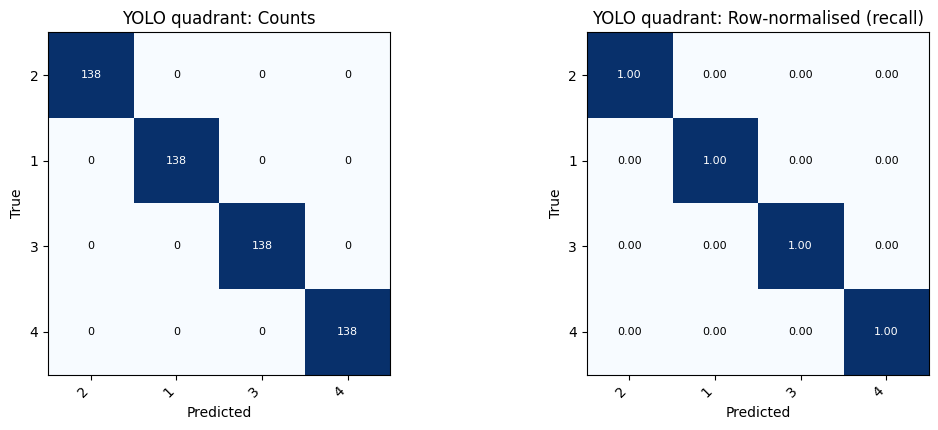

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3466.6±418.7 MB/s, size: 3395.0 KB)
val: Scanning /content/dentex_work/yolo_quadrant/labels/test... 138 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 138/138 120.7it/s 1.1s
val: New cache created: /content/dentex_work/yolo_quadrant/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 1.4s/it 12.3s
                   all        138        552      0.999          1      0.995      0.732
Speed: 3.3ms preprocess, 12.5ms inference, 0.0ms loss, 2.6ms postprocess per image
Results saved to /content/runs/detect/val

==================== ENUM ====================
YOLO found 3575/3603 true teeth (99.2%)
              precision    recall  f1-score   support

           1      0.971     0.945     0.958  

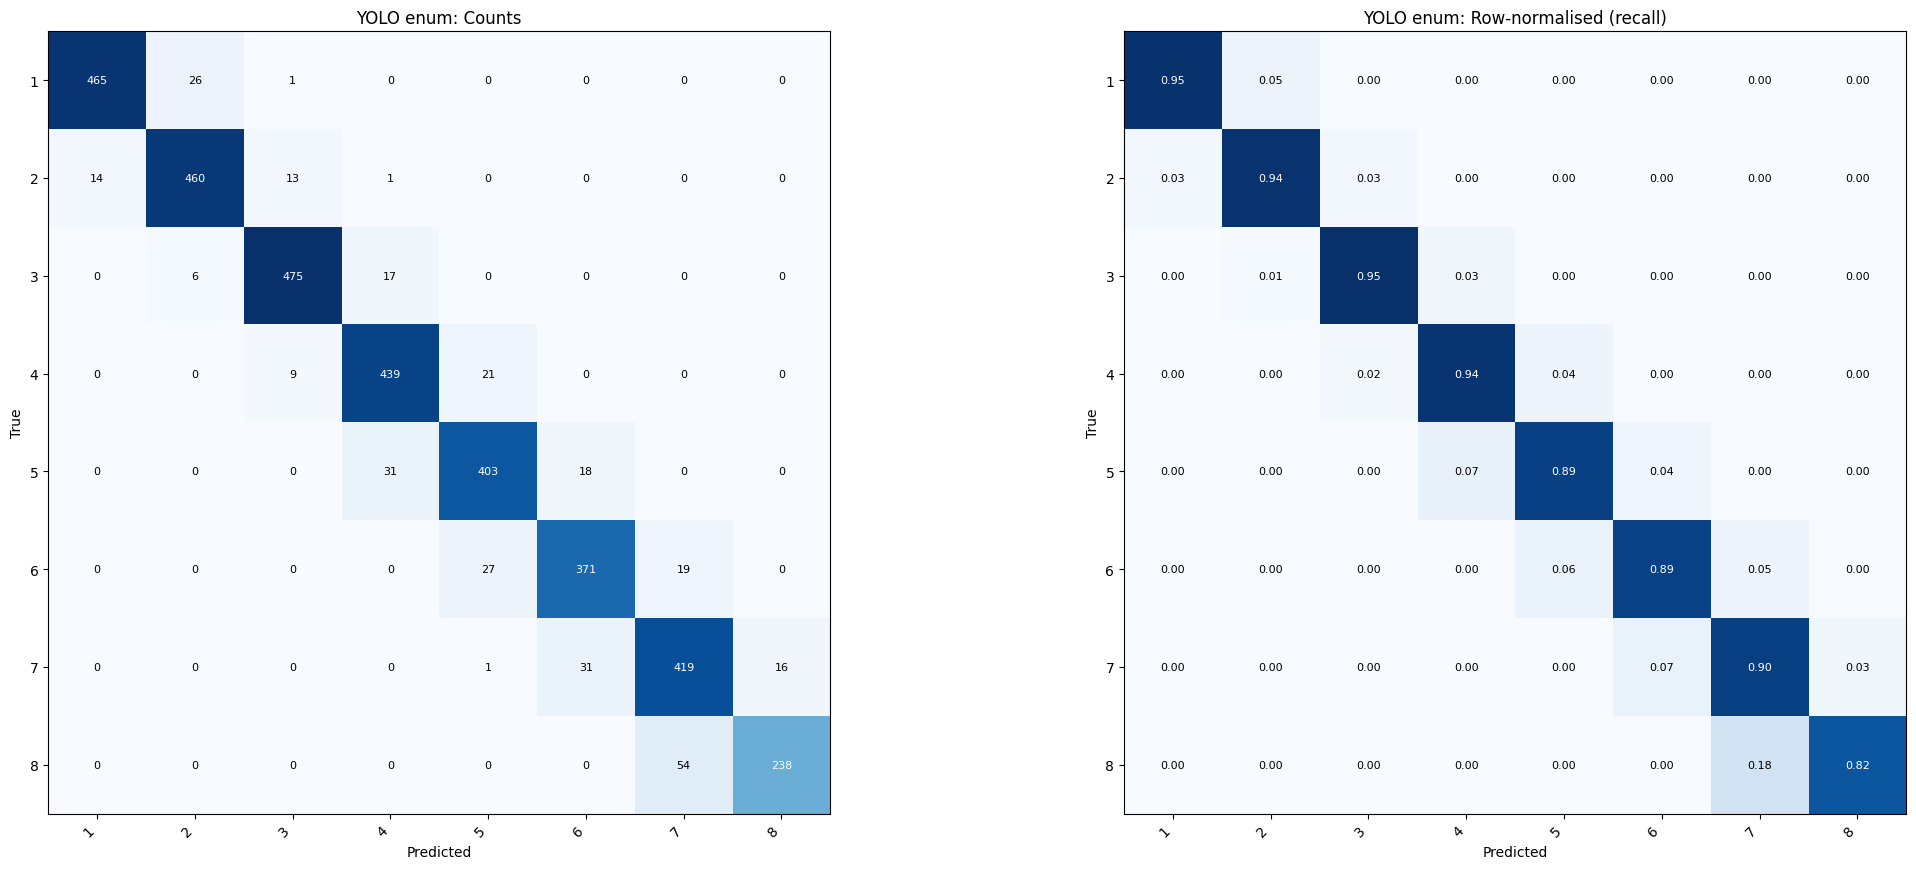

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,128,680 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3256.1±321.9 MB/s, size: 3301.1 KB)
val: Scanning /content/dentex_work/yolo_enum/labels/test... 126 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 126/126 175.5it/s 0.7s
val: New cache created: /content/dentex_work/yolo_enum/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 1.5s/it 12.4s
                   all        126       3603      0.923      0.928      0.958      0.548
Speed: 4.1ms preprocess, 12.8ms inference, 0.0ms loss, 2.9ms postprocess per image
Results saved to /content/runs/detect/val-2

==================== DISEASE ====================
YOLO found 514/789 true teeth (65.1%)
                   precision    recall  f1-score   support

         Impacted      0.921     0.969     0.

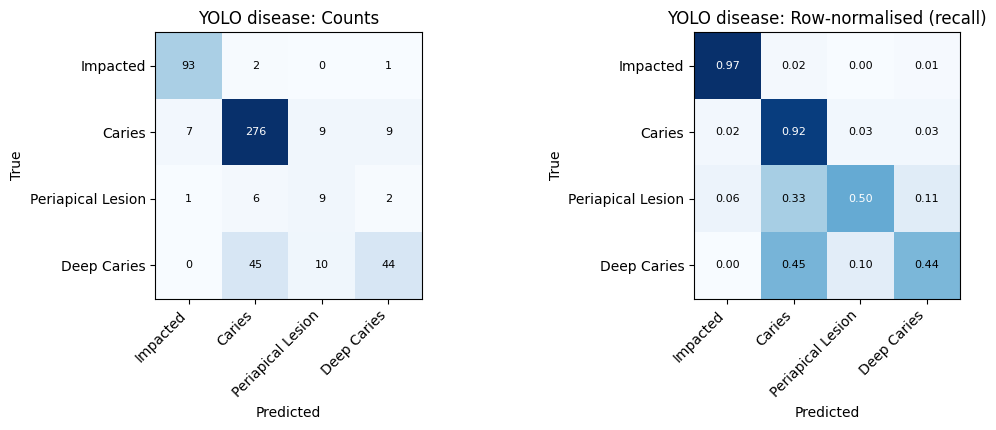

Ultralytics 8.4.213 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 72 layers, 11,127,132 parameters, 0 gradients, 28.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3651.9±415.9 MB/s, size: 4357.2 KB)
val: Scanning /content/dentex_work/yolo_disease/labels/test... 141 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 141/141 143.2it/s 1.0s
val: New cache created: /content/dentex_work/yolo_disease/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 9/9 1.7s/it 15.0s
                   all        141        789       0.48      0.539      0.466        0.3
Speed: 3.5ms preprocess, 13.6ms inference, 0.0ms loss, 3.0ms postprocess per image
Results saved to /content/runs/detect/val-3


In [ ]:
# Evaluation metrics

def iou(a, b):
    ix1, iy1, ix2, iy2 = max(a[0], b[0]), max(a[1], b[1]), min(a[2], b[2]), min(a[3], b[3])
    inter = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    union = (a[2]-a[0])*(a[3]-a[1]) + (b[2]-b[0])*(b[3]-b[1]) - inter
    return inter / union if union > 0 else 0

def get_predictions(task, iou_thr=0.5):
    cfg, ds = TASKS[task], DS[task]
    model = YOLO(str(best_path(task)))
    data = json.load(open(cfg["json"]))
    id2idx = {c: i for i, c in enumerate(ds["ids"])}
    test_set = set((BASE / f"test_{task}.txt").read_text().split())
    im_by_id = {im["id"]: im for im in data["images"] if im["file_name"] in test_set}
    gts = {}
    for a in data["annotations"]:
        if a["image_id"] in im_by_id: gts.setdefault(a["image_id"], []).append(a)
    y_true, y_pred = [], []                       # -1 = tooth missed by YOLO
    for iid, im in im_by_id.items():
        r = model.predict(str(ds["root"] / "images" / "test" / im["file_name"]),
                          imgsz=IMGSZ, conf=0.1, device=DEVICE, verbose=False)[0]
        pb = r.boxes.xyxy.cpu().numpy(); pc = r.boxes.cls.cpu().numpy().astype(int)
        for a in gts.get(iid, []):
            x, y, w, h = a["bbox"]; g = [x, y, x + w, y + h]
            ious = [iou(g, p) for p in pb]
            b = int(np.argmax(ious)) if ious else -1
            y_true.append(id2idx[a[cfg["key"]]])
            y_pred.append(int(pc[b]) if b >= 0 and ious[b] >= iou_thr else -1)
    return np.array(y_true), np.array(y_pred)

def full_evaluation(task):
    ds = DS[task]; names = ds["names"]; labels = list(range(len(names)))
    y_true, y_pred = get_predictions(task)
    found = y_pred >= 0
    yt, yp = y_true[found], y_pred[found]

    print(f"\n{'='*20} {task.upper()} {'='*20}")
    print(f"YOLO found {found.sum()}/{len(found)} true teeth ({found.mean():.1%})")
    print(classification_report(yt, yp, labels=labels, target_names=names, zero_division=0, digits=3))

    cm = confusion_matrix(yt, yp, labels=labels)
    cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(1, 2, figsize=(max(10, 2.8*len(names)), max(4, 1.1*len(names))))
    for a_, mat, title, fmt in [(ax[0], cm, "Counts", "{:d}"), (ax[1], cmn, "Row-normalised (recall)", "{:.2f}")]:
        a_.imshow(mat, cmap="Blues"); a_.set_title(f"YOLO {task}: {title}")
        a_.set_xticks(labels); a_.set_xticklabels(names, rotation=45, ha="right")
        a_.set_yticks(labels); a_.set_yticklabels(names)
        a_.set_xlabel("Predicted"); a_.set_ylabel("True")
        for i in labels:
            for j in labels:
                a_.text(j, i, fmt.format(mat[i, j]), ha="center", va="center",
                        color="white" if mat[i, j] > mat.max()/2 else "black", fontsize=8)
    plt.tight_layout(); plt.savefig(BASE / f"cm_yolo_{task}.png", dpi=150); plt.show()

    m = YOLO(str(best_path(task))).val(data=str(ds["root"] / "data.yaml"), split="test",
                                       imgsz=IMGSZ, device=DEVICE, verbose=False)
    pm, rm, fm, _ = precision_recall_fscore_support(yt, yp, labels=labels, average="macro", zero_division=0)
    pw, rw, fw, _ = precision_recall_fscore_support(yt, yp, labels=labels, average="weighted", zero_division=0)
    return dict(task=task, model="YOLOv8s",
                accuracy=accuracy_score(yt, yp),
                macro_precision=pm, macro_recall=rm, macro_f1=fm,
                weighted_precision=pw, weighted_recall=rw, weighted_f1=fw,
                teeth_found=found.mean(),
                accuracy_missed_as_errors=float(np.mean(y_true == y_pred)),
                mAP50=float(m.box.map50), mAP50_95=float(m.box.map))

RESULTS = {t: full_evaluation(t) for t in ["quadrant", "enum", "disease"]}

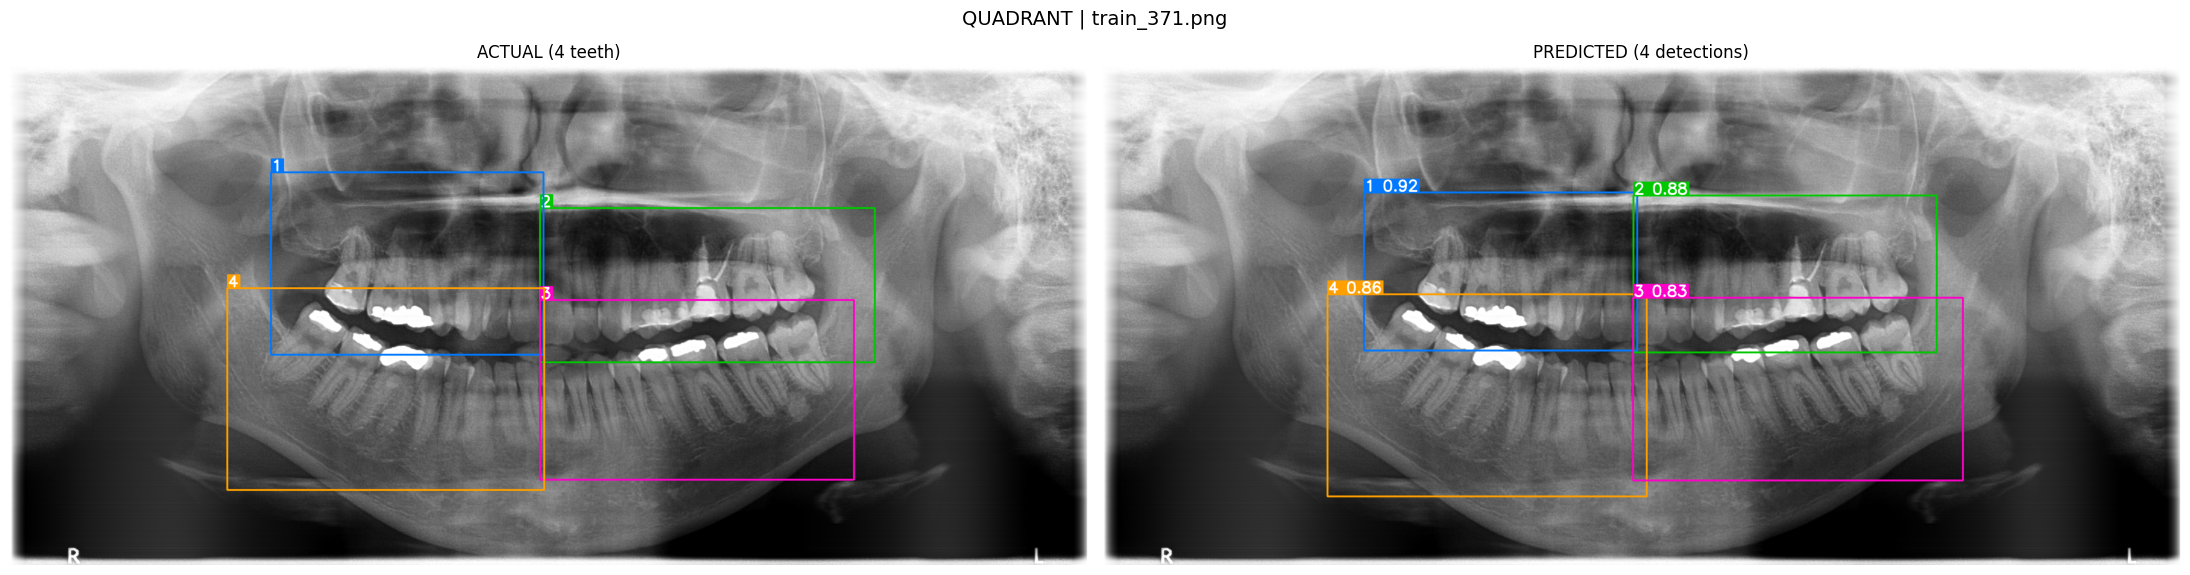

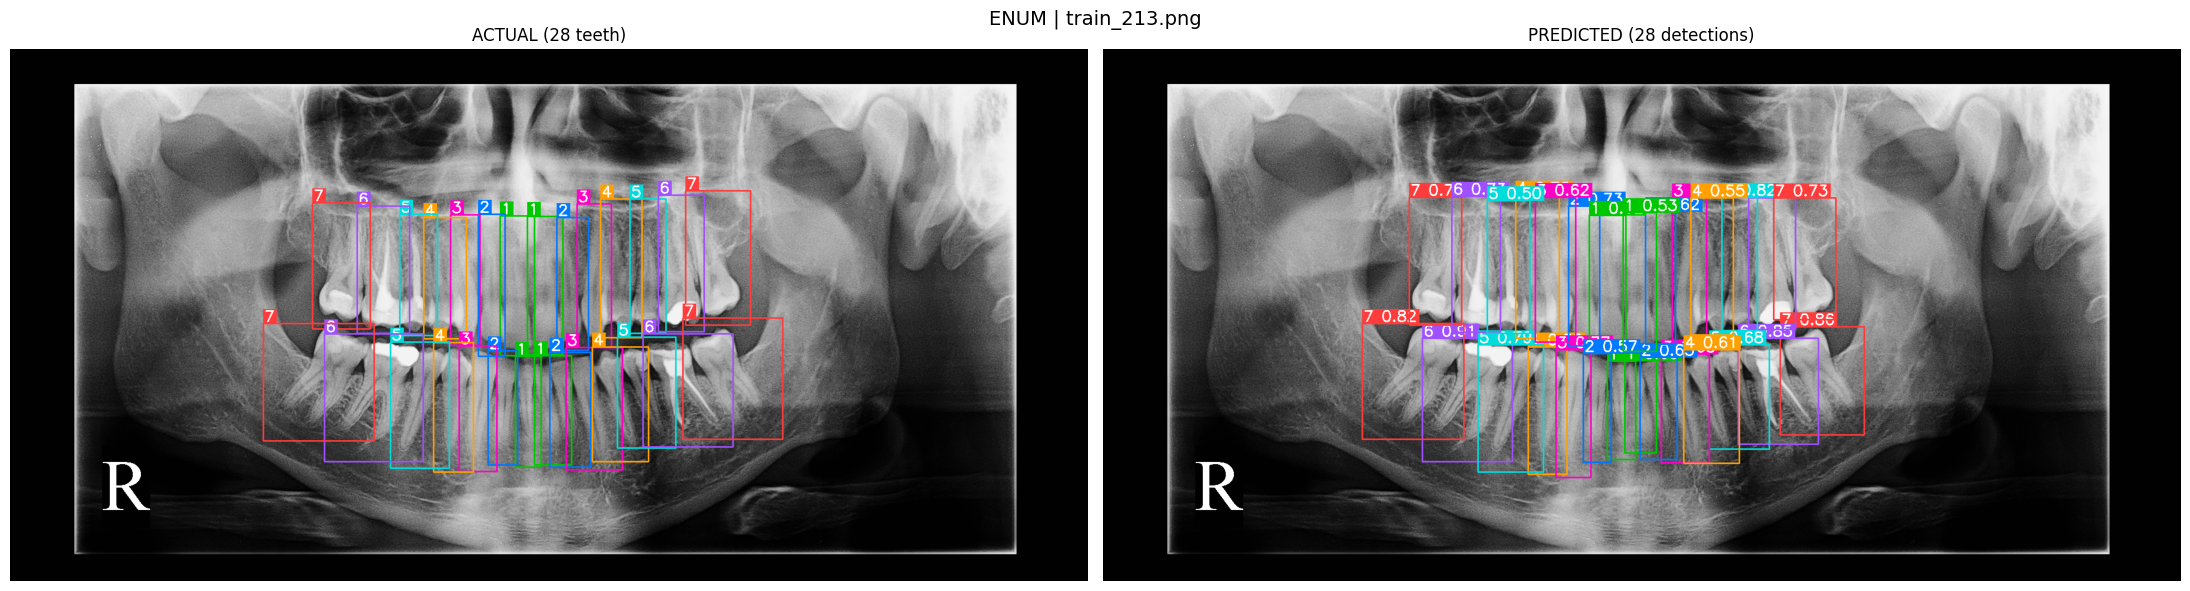

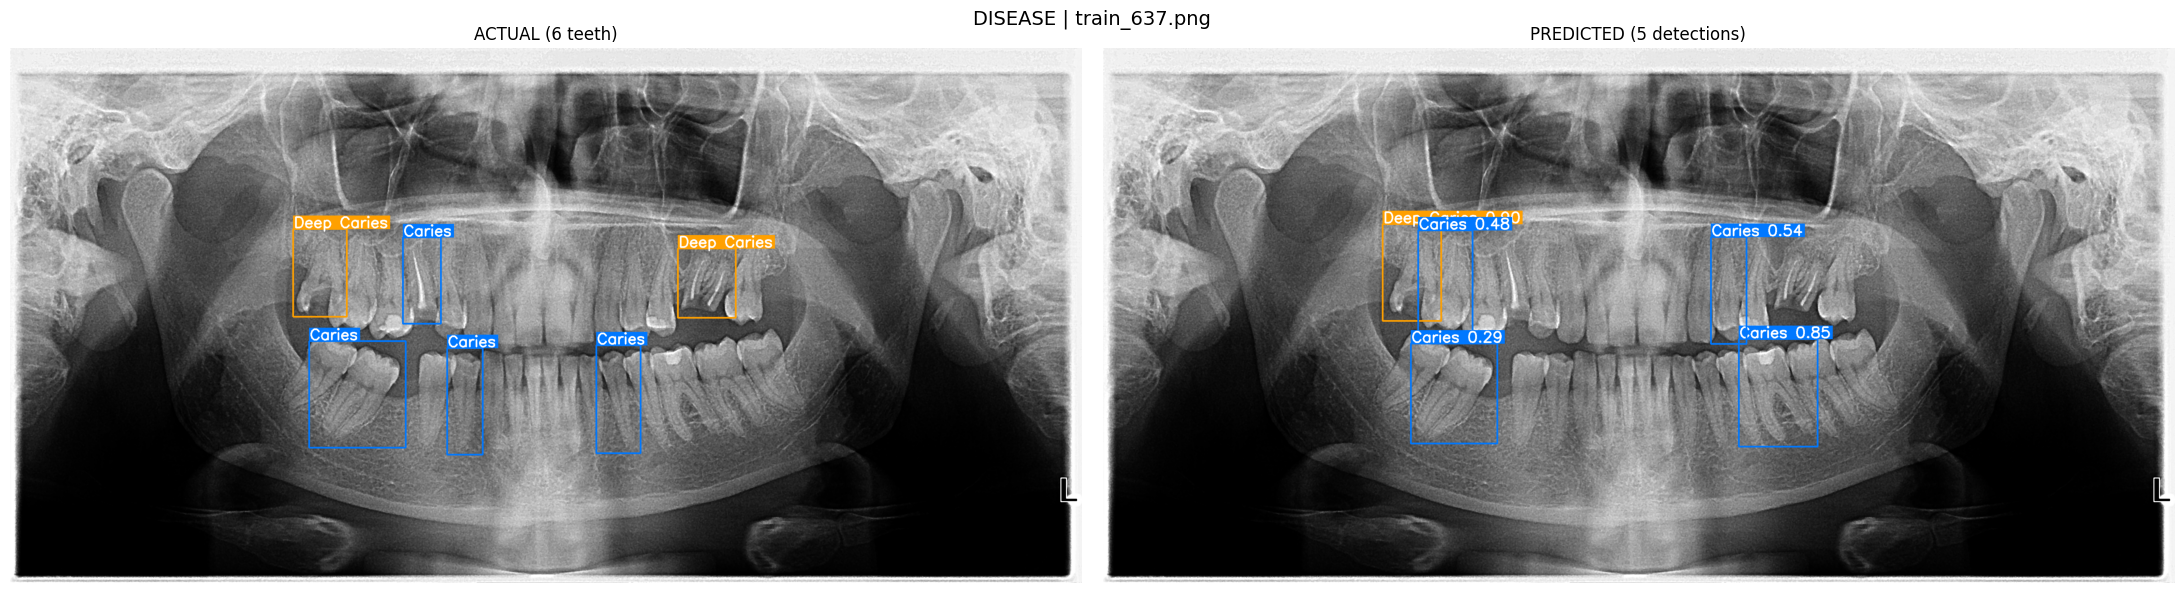

In [ ]:
COLORS = [(0, 200, 0), (0, 120, 255), (255, 0, 200), (255, 160, 0),
          (0, 220, 220), (160, 80, 255), (255, 60, 60), (120, 200, 60)]

def draw_boxes(img, boxes, texts, classes):
    out = img.copy(); s = max(img.shape[1] / 1500, 0.6)
    for (x1, y1, x2, y2), t, c in zip(boxes, texts, classes):
        col = COLORS[c % len(COLORS)]
        cv2.rectangle(out, (int(x1), int(y1)), (int(x2), int(y2)), col, max(2, int(2*s)))
        (tw, th), _ = cv2.getTextSize(t, cv2.FONT_HERSHEY_SIMPLEX, 0.7*s, max(1, int(2*s)))
        y0 = max(int(y1), th + 6)
        cv2.rectangle(out, (int(x1), y0 - th - 6), (int(x1) + tw + 4, y0), col, -1)
        cv2.putText(out, t, (int(x1) + 2, y0 - 4), cv2.FONT_HERSHEY_SIMPLEX, 0.7*s, (255, 255, 255), max(1, int(2*s)))
    return out

def show_random_detection(task, filename=None, conf=0.25, seed=None):
    cfg, ds = TASKS[task], DS[task]
    data = json.load(open(cfg["json"]))
    id2idx = {c: i for i, c in enumerate(ds["ids"])}
    test_files = sorted((BASE / f"test_{task}.txt").read_text().split())
    filename = filename or random.Random(seed).choice(test_files)
    im = next(i for i in data["images"] if i["file_name"] == filename)
    img = cv2.cvtColor(cv2.imread(str(ds["root"] / "images" / "test" / filename)), cv2.COLOR_BGR2RGB)

    gt = [a for a in data["annotations"] if a["image_id"] == im["id"]]
    g_boxes = [[a["bbox"][0], a["bbox"][1], a["bbox"][0]+a["bbox"][2], a["bbox"][1]+a["bbox"][3]] for a in gt]
    g_cls = [id2idx[a[cfg["key"]]] for a in gt]
    g_txt = [ds["names"][c] for c in g_cls]

    r = YOLO(str(best_path(task))).predict(str(ds["root"] / "images" / "test" / filename),
                                           imgsz=IMGSZ, conf=conf, device=DEVICE, verbose=False)[0]
    p_boxes = r.boxes.xyxy.cpu().numpy(); p_cls = r.boxes.cls.cpu().numpy().astype(int)
    p_txt = [f"{ds['names'][c]} {s:.2f}" for c, s in zip(p_cls, r.boxes.conf.cpu().numpy())]

    fig, ax = plt.subplots(1, 2, figsize=(22, 6))
    ax[0].imshow(draw_boxes(img, g_boxes, g_txt, g_cls)); ax[0].set_title(f"ACTUAL ({len(gt)} teeth)")
    ax[1].imshow(draw_boxes(img, p_boxes, p_txt, p_cls)); ax[1].set_title(f"PREDICTED ({len(p_boxes)} detections)")
    for a_ in ax: a_.axis("off")
    plt.suptitle(f"{task.upper()} | {filename}", fontsize=14)
    plt.tight_layout(); plt.savefig(BASE / f"detect_{task}_{Path(filename).stem}.png", dpi=150); plt.show()

for t in ["quadrant", "enum", "disease"]:
    show_random_detection(t)

In [ ]:
table = pd.DataFrame(RESULTS.values()).round(3)
table.to_csv(BASE / "results_yolo.csv", index=False)

for pattern in ["cm_yolo_*.png", "detect_*.png", "results_yolo.csv", "test_*.txt"]:
    for f in BASE.glob(pattern):
        shutil.copy(f, DRIVE / f.name)
tabletable = pd.DataFrame(RESULTS.values()).round(3)
table.to_csv(BASE / "results_yolo.csv", index=False)

for pattern in ["cm_yolo_*.png", "detect_*.png", "results_yolo.csv", "test_*.txt"]:
    for f in BASE.glob(pattern):
        shutil.copy(f, DRIVE / f.name)
table

,task,model,accuracy,macro_precision,macro_recall,macro_f1,weighted_precision,weighted_recall,weighted_f1,teeth_found,accuracy_missed_as_errors,mAP50,mAP50_95
0,quadrant,YOLOv8s,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.995,0.732
1,enum,YOLOv8s,0.915,0.915,0.909,0.911,0.916,0.915,0.915,0.992,0.908,0.958,0.548
2,disease,YOLOv8s,0.821,0.717,0.708,0.695,0.826,0.821,0.812,0.651,0.535,0.466,0.300
